In [2]:
import os
os.chdir("D:/tmp_workplace/dynamic_structure/250331/C_VRV/structure_feature_detection_evaluation/28S_rRNA_include")
import matplotlib.pyplot as plt
import numpy as np
from scipy import sparse
from scipy.stats import mannwhitneyu
import pandas as pd

In [3]:
matrix = np.zeros((1015,1015))
with open("28S_rRNA_merge_RICseq_10_KR_10_remake10_merge_5_KR_5_OEmask_fill_diagonal_filter_gaussian.bedpe","r") as f:
    for line in f:
        if "chrom" in line:
            continue
        else:
            sub = line.strip().split()
            left = int(sub[1])
            right = int(sub[4])
            if left < right:
                matrix[int(left/5),int(right/5)] = 1
                matrix[int(right/5),int(left/5)] = 1

In [4]:
pairs = []
with open("28S_rRNA_c.bedpe","r")as f:
    for line in f:
        if "chrom" in line:
            continue
        else:
            sub = line.strip().split()
            left = int(sub[1])
            right = int(sub[4])
            if left < right:
                pairs.append((left,right))

In [5]:
sup = []
wsup = []

for pair in pairs:
    left = pair[0]
    right = pair[1]
    if matrix[int(left/5),int(right/5)] == 1:
        sup.append(pair)
    else:
        wsup.append(pair)

print(len(pairs),len(sup),len(wsup))

1495 1251 244


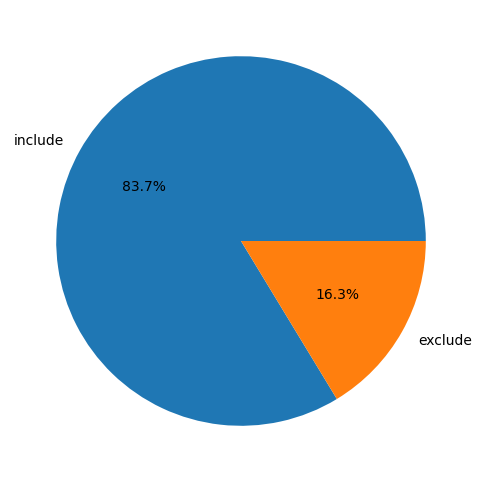

In [7]:
labels = 'include', 'exclude'
sizes = [len(sup), len(wsup)]

fig, ax = plt.subplots(figsize=(6,6))
ax.pie(sizes, labels=labels, autopct='%1.1f%%')
plt.savefig("proportion.pdf",format="pdf")